### Credit Risk Classifier using Loan Application Data Project

In [103]:
# importing necessary libraries 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 

In [104]:
# importing dataset and checking head 
df = pd.read_csv("Loan_Default.csv")
df.head(10)

,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,...,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1
0,24890,2019,cf,Sex Not Available,nopre,type1,p1,l1,nopc,nob/c,...,EXP,758,CIB,25-34,to_inst,98.728814,south,direct,1,45.0
1,24891,2019,cf,Male,nopre,type2,p1,l1,nopc,b/c,...,EQUI,552,EXP,55-64,to_inst,NaN,North,direct,1,NaN
2,24892,2019,cf,Male,pre,type1,p1,l1,nopc,nob/c,...,EXP,834,CIB,35-44,to_inst,80.019685,south,direct,0,46.0
3,24893,2019,cf,Male,nopre,type1,p4,l1,nopc,nob/c,...,EXP,587,CIB,45-54,not_inst,69.376900,North,direct,0,42.0
4,24894,2019,cf,Joint,pre,type1,p1,l1,nopc,nob/c,...,CRIF,602,EXP,25-34,not_inst,91.886544,North,direct,0,39.0
5,24895,2019,cf,Joint,pre,type1,p1,l1,nopc,nob/c,...,EXP,864,EXP,35-44,not_inst,70.089286,North,direct,0,40.0
6,24896,2019,cf,Joint,pre,type1,p3,l1,nopc,nob/c,...,EXP,860,EXP,55-64,to_inst,79.109589,North,direct,0,44.0
7,24897,2019,NaN,Female,nopre,type1,p4,l1,nopc,nob/c,...,CIB,863,CIB,55-64,to_inst,86.525974,North,direct,0,42.0
8,24898,2019,cf,Joint,nopre,type1,p3,l1,nopc,nob/c,...,CIB,580,EXP,55-64,to_inst,78.765690,central,direct,0,44.0
9,24899,2019,cf,Sex Not Available,nopre,type3,p3,l1,nopc,nob/c,...,CIB,788,EXP,55-64,to_inst,63.444767,south,direct,0,30.0


In [105]:
# just looking through and understanding the data here and also in kaggle descriptions 
for col in df.select_dtypes(include='object').columns:
    print(f"{df[col].value_counts()}\n")

loan_limit
cf     135348
ncf      9978
Name: count, dtype: int64

Gender
Male                 42346
Joint                41399
Sex Not Available    37659
Female               27266
Name: count, dtype: int64

approv_in_adv
nopre    124621
pre       23141
Name: count, dtype: int64

loan_type
type1    113173
type2     20762
type3     14735
Name: count, dtype: int64

loan_purpose
p3    55934
p4    54799
p1    34529
p2     3274
Name: count, dtype: int64

Credit_Worthiness
l1    142344
l2      6326
Name: count, dtype: int64

open_credit
nopc    148114
opc        556
Name: count, dtype: int64

business_or_commercial
nob/c    127908
b/c       20762
Name: count, dtype: int64

Neg_ammortization
not_neg    133420
neg_amm     15129
Name: count, dtype: int64

interest_only
not_int     141560
int_only      7110
Name: count, dtype: int64

lump_sum_payment
not_lpsm    145286
lpsm          3384
Name: count, dtype: int64

construction_type
sb    148637
mh        33
Name: count, dtype: int64

occupancy_t

In [106]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148670 entries, 0 to 148669
Data columns (total 34 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   ID                         148670 non-null  int64  
 1   year                       148670 non-null  int64  
 2   loan_limit                 145326 non-null  object 
 3   Gender                     148670 non-null  object 
 4   approv_in_adv              147762 non-null  object 
 5   loan_type                  148670 non-null  object 
 6   loan_purpose               148536 non-null  object 
 7   Credit_Worthiness          148670 non-null  object 
 8   open_credit                148670 non-null  object 
 9   business_or_commercial     148670 non-null  object 
 10  loan_amount                148670 non-null  int64  
 11  rate_of_interest           112231 non-null  float64
 12  Interest_rate_spread       112031 non-null  float64
 13  Upfront_charges            10

In [107]:
df.shape

(148670, 34)

In [108]:
print(df.columns.tolist())


['ID', 'year', 'loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'property_value', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'income', 'credit_type', 'Credit_Score', 'co-applicant_credit_type', 'age', 'submission_of_application', 'LTV', 'Region', 'Security_Type', 'Status', 'dtir1']


In [109]:
print(df['Status'].value_counts())

Status
0    112031
1     36639
Name: count, dtype: int64


In [110]:
print(df['Status'].value_counts(normalize=True) * 100)


Status
0    75.355485
1    24.644515
Name: proportion, dtype: float64


### Data Preprocessing 

In [111]:
### remove non-predictive features, remove duplicates
### handle missing values (choose to zero, null, remove, etc. and which ones)
### encode categorical features
### scale numerical values

In [112]:
# dropping id and year bc doesn't matter, dropping duplicates 
# *only run once to avoid error
df = df.drop(columns=['ID', 'year'])

In [113]:
# dropping duplicate rows so model can learn real patterns 
df = df.drop_duplicates()

In [114]:
print(df.shape)

(148670, 32)


In [115]:
# there were no duplicates in the dataset so now I'm going to handle missing values.

In [116]:
# checking where missing values are and if it plagues the dataset or not
missing = df.isnull().sum() # adding the number of null values (*in a row?)
missing_df = pd.DataFrame({'Missing Count': missing, 'Percentage': (missing/len(df))*100})
print(missing_df[missing_df['Missing Count'] > 0])

                           Missing Count  Percentage
loan_limit                          3344    2.249277
approv_in_adv                        908    0.610749
loan_purpose                         134    0.090133
rate_of_interest                   36439   24.509989
Interest_rate_spread               36639   24.644515
Upfront_charges                    39642   26.664425
term                                  41    0.027578
Neg_ammortization                    121    0.081388
property_value                     15098   10.155378
income                              9150    6.154571
age                                  200    0.134526
submission_of_application            200    0.134526
LTV                                15098   10.155378
dtir1                              24121   16.224524


In [117]:
# okay so it seems like most columns have small percentages of missing data 
# but rate_of_interest, interest_rate_spread, and upfront_charges have over 24% 
# missing data and dtir1 has over 16% missing data. the thing is, 
# rate_of_interest and dtir1 are important for predicting defaulting risks
# so im gonna keep those and fill them 

In [118]:
# fill numeric values with median amount
num_cols = df.select_dtypes(include='number').columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

# fill cat values with most frequent value or mode 
cat_cols = df.select_dtypes(include='object').columns
df[cat_cols] = df[cat_cols].fillna(df[cat_cols].mode().iloc[0])

In [119]:
# checking for missing values to make sure it's fixed 
print(df.isnull().sum().sum())

0


In [120]:
# yay so i got 0. meaning there are no more missing values.
# next part is encoding categorical columns so i wanna make sure everything
# is numerical so that we can calculate and the model can learn with those
# calculations and actually be able to make predictions bc u can't do that
# with values like "type1" or "male" 

In [121]:
# using manual mapping so that i can assign values to columns on my own
# using labelencoder for ones i trust to manually encode
from sklearn.preprocessing import LabelEncoder

df['Credit_Worthiness'] = df['Credit_Worthiness'].map({'l1': 0, 'l2': 1})
df['loan_limit'] = df['loan_limit'].map({'ncf': 0, 'cf': 1})
df['approv_in_adv'] = df['approv_in_adv'].map({'nopre': 0, 'pre': 1})
df['open_credit'] = df['open_credit'].map({'nopc': 0, 'opc': 1})
df['business_or_commercial'] = df['business_or_commercial'].map({'nob/c': 0, 'ob/c': 1})
df['Neg_ammortization'] = df['Neg_ammortization'].map({'not_neg': 0, 'neg_amm': 1})
df['interest_only'] = df['interest_only'].map({'not_int': 0, 'int_only': 1})
df['lump_sum_payment'] = df['lump_sum_payment'].map({'not_lpsm': 0, 'lpsm': 1})
df['Security_Type'] = df['Security_Type'].map({'direct': 0, 'indirect': 1})
df['construction_type'] = df['construction_type'].map({'sb': 0, 'mh': 1})
df['occupancy_type'] = df['occupancy_type'].map({'pr': 0, 'sr': 1, 'ir': 2})

le = LabelEncoder()
nominal_cols = ['Gender', 'loan_type', 'loan_purpose', 'credit_type', 
                'Region', 'Secured_by', 'submission_of_application', 
                'co-applicant_credit_type', 'total_units']

for col in nominal_cols:
    df[col] = le.fit_transform(df[col])

# checking to make sure all columns are numerical :D
print(df.dtypes)
print("\nAny remaining object columns:", df.select_dtypes(include='object').columns.tolist())


loan_limit                     int64
Gender                         int64
approv_in_adv                  int64
loan_type                      int64
loan_purpose                   int64
Credit_Worthiness              int64
open_credit                    int64
business_or_commercial       float64
loan_amount                    int64
rate_of_interest             float64
Interest_rate_spread         float64
Upfront_charges              float64
term                         float64
Neg_ammortization              int64
interest_only                  int64
lump_sum_payment               int64
property_value               float64
construction_type              int64
occupancy_type                 int64
Secured_by                     int64
total_units                    int64
income                       float64
credit_type                    int64
Credit_Score                   int64
co-applicant_credit_type       int64
age                           object
submission_of_application      int64
L

In [122]:
# age is still an object bc its a range so gonna fix that
# removes dash and averages age ranges into one number
# estimating returns for edge cases (>74 and <25)
def age_to_midpoint(age):
    if age == '>74':
        return 77
    elif age == '<25':
        return 22
    else:
        parts = age.split('-')
        return (int(parts[0]) + int(parts[1])) / 2

df['age'] = df['age'].apply(age_to_midpoint)

print(df['age'].value_counts())
print(df['age'].dtype)

age
49.5    34920
39.5    32818
59.5    32534
69.5    20744
29.5    19142
77.0     7175
22.0     1337
Name: count, dtype: int64
float64


### Feature and Label Definition

In [123]:
# now that everything is numerical :D going to scale these numerical features
# as per pdf instructions 

from sklearn.preprocessing import StandardScaler 

# going to now use Status as my target variable bc it's what im trying to 
# predict rn which is if the person defaulted (1) for yes and (0) for no
# X is all input features except Status where the model learns from
# y is just the status column which is what the model learns to predict 

X = df.drop(columns=['Status'])
y = df['Status']

# scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# convert back
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

print(X_scaled.describe().round(2))


       loan_limit     Gender  approv_in_adv  loan_type  loan_purpose  \
count   148670.00  148670.00      148670.00  148670.00     148670.00   
mean         0.00       0.00          -0.00       0.00         -0.00   
std          1.00       1.00           1.00       1.00          1.00   
min         -3.73      -1.53          -0.43      -0.52         -1.65   
25%          0.27      -0.58          -0.43      -0.52         -0.77   
50%          0.27       0.37          -0.43      -0.52          0.10   
75%          0.27       1.32          -0.43      -0.52          0.98   
max          0.27       1.32           2.33       2.56          0.98   

       Credit_Worthiness  open_credit  business_or_commercial  loan_amount  \
count          148670.00    148670.00                127908.0    148670.00   
mean                0.00         0.00                     0.0        -0.00   
std                 1.00         1.00                     0.0         1.00   
min                -0.21        -0.06  

### Train-Test Split

In [124]:
# there's already 148k+ loan records where the outcome is known so now splitting
# into two groups so that one group is used for model training and the other
# group is hidden completely until after the model is trained 
# using 80/20 split like said in pdf.. using random_state=42 to shuffle before
# dividing. in real banks, this is similar because my model would train on
# historical loans and then it would basically get deployed to evaluate brand
# new applicants the model hasn't seen before. so this test is simulating that
# scenario to show me how my model would run in the real world.  

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, 
    test_size=0.2, 
    random_state=42
)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

Training set size: (118936, 31)
Testing set size: (29734, 31)


### Model Training 

In [125]:
X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

# my code broke bc i had nan values so im adding this so my code works :D
print(X_train.isnull().sum().sum())
print(X_test.isnull().sum().sum())

0
0


In [126]:
## for this imma use logistic regression and random forest classifier
# they r my favorite because like they're mainstream which is always a safe bet

from sklearn.linear_model import LogisticRegression
# logreg is finding the best mathematical line that separates defaulter
# applicants from non-defaulter applications across all 31 features 
from sklearn.ensemble import RandomForestClassifier 
# rand for is building decision trees and each one learns slightly diff
# patterns from random subsets of the data

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

print("yo ts worked gng good job.")

yo ts worked gng good job.


### Evaluation 

Log Reg Accuracy: 0.7788
Rand For Accuracy: 0.9999

Log Reg Report:               precision    recall  f1-score   support

           0       0.79      0.95      0.87     22494
           1       0.62      0.24      0.34      7240

    accuracy                           0.78     29734
   macro avg       0.71      0.59      0.60     29734
weighted avg       0.75      0.78      0.74     29734

Rand For Report:               precision    recall  f1-score   support

           0       1.00      1.00      1.00     22494
           1       1.00      1.00      1.00      7240

    accuracy                           1.00     29734
   macro avg       1.00      1.00      1.00     29734
weighted avg       1.00      1.00      1.00     29734



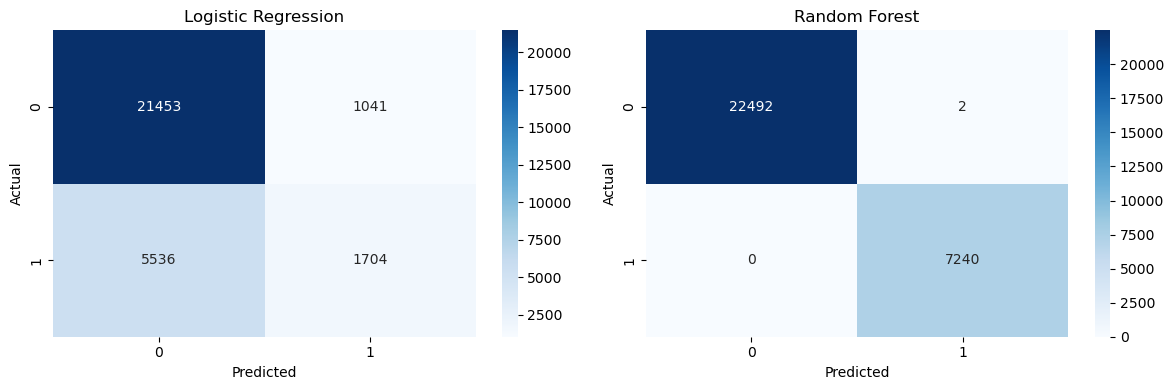

In [127]:
# now is the part we all were waiting for.. or just me but thats cool or wtv
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt 

# gonna make predicitions using the hidden test set to predict 0 or 1 
y_pred_lr = lr.predict(X_test)
y_pred_rf = rf.predict(X_test)

# checking the accuracy of my model's predictions ... im scared to see
# what percentage my models got right ... 
print("Log Reg Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))
print("Rand For Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))

# classification report. precision so what percentage of ppl marked high risk
# actually was high risk? recall so of everyone who did default what percent
# did the model catch? F1 score so what's the balance between precision and
# recall combined 
print("\nLog Reg Report:", classification_report(y_test, y_pred_lr))
print("Rand For Report:", classification_report(y_test, y_pred_rf))

# confusion matrix because im confused. nah jk but where did my model get
# confused?? (top left - correctly predicted no default) (top right - pred 
# default but was fine) (botton left - predicted fine but defaulted) (bottom right - 
# correctly predicted default)
fig, axes = plt.subplots(1, 2, figsize=(12,4))

sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', ax=axes[0], cmap='Blues')
axes[0].set_title('Logistic Regression')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', ax=axes[1], cmap='Blues')
axes[1].set_title('Random Forest')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [128]:
# umm so y my random forest 99% accurate gng thats not good.
# checking...
print(X.columns.tolist())

['loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose', 'Credit_Worthiness', 'open_credit', 'business_or_commercial', 'loan_amount', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges', 'term', 'Neg_ammortization', 'interest_only', 'lump_sum_payment', 'property_value', 'construction_type', 'occupancy_type', 'Secured_by', 'total_units', 'income', 'credit_type', 'Credit_Score', 'co-applicant_credit_type', 'age', 'submission_of_application', 'LTV', 'Region', 'Security_Type', 'dtir1']


In [ ]:
# alr so looking back at the kaggle discussion and everything i realized that
# some of my columns are almost exclusively assigned to loans that are
# already flagged at high risk lmaoo so random forest is good bc it found
# that pattern and used it (target leakage) so now imma rerun this dropping
# those columns    

In [129]:
X = df.drop(columns=['Status', 'rate_of_interest', 'Interest_rate_spread', 'Upfront_charges'])
y = df['Status']

# rescaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)
X_scaled = X_scaled.fillna(0)

# resplitting
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

# resplitting
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

print("Retrained successfully!")

Retrained successfully!


Log Reg Accuracy: 0.7779
Rand For Accuracy: 0.8913

Log Reg Report:               precision    recall  f1-score   support

           0       0.79      0.97      0.87     22494
           1       0.65      0.19      0.29      7240

    accuracy                           0.78     29734
   macro avg       0.72      0.58      0.58     29734
weighted avg       0.75      0.78      0.73     29734

Rand For Report:               precision    recall  f1-score   support

           0       0.88      0.99      0.93     22494
           1       0.93      0.60      0.73      7240

    accuracy                           0.89     29734
   macro avg       0.91      0.79      0.83     29734
weighted avg       0.90      0.89      0.88     29734



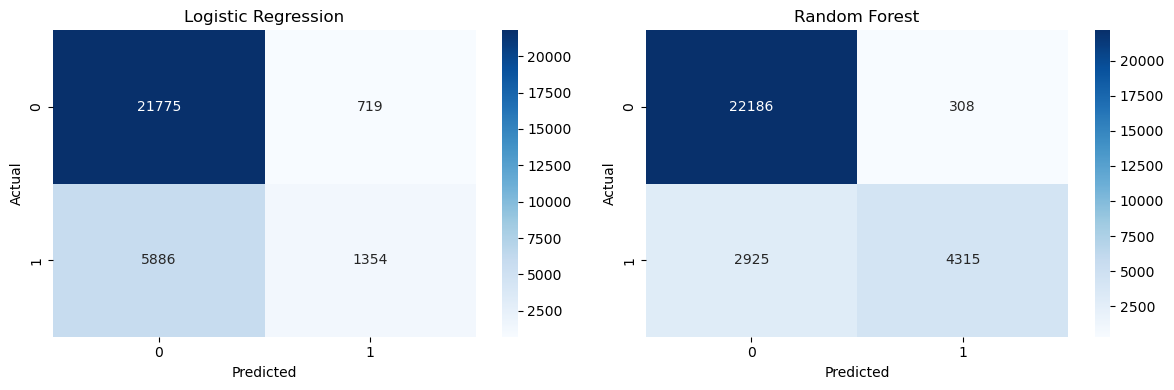

In [ ]:
# literally just copied and pasted my previous cell now that it's retrained
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt 

# gonna make predicitions using the hidden test set to predict 0 or 1 
y_pred_lr = lr.predict(X_test)
y_pred_rf = rf.predict(X_test)

# checking the accuracy of my model's predictions ... im scared to see
# what percentage my models got right ... 
print("Log Reg Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))
print("Rand For Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))

# classification report. precision so what percentage of ppl marked high risk
# actually was high risk? recall so of everyone who did default what percent
# did the model catch? F1 score so what's the balance between precision and
# recall combined 
print("\nLog Reg Report:", classification_report(y_test, y_pred_lr))
print("Rand For Report:", classification_report(y_test, y_pred_rf))

# confusion matrix because im confused. nah jk but where did my model get
# confused?? (top left - correctly predicted no default) (top right - pred 
# default but was fine) (botton left - predicted fine but defaulted) (bottom right - 
# correctly predicted default)
fig, axes = plt.subplots(1, 2, figsize=(12,4))

sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', ax=axes[0], cmap='Blues')
axes[0].set_title('Logistic Regression')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', ax=axes[1], cmap='Blues')
axes[1].set_title('Random Forest')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

### Model Comparison

In [132]:
# heyyy finally done yay

print(f"{'Metric':<25} {'Log Reg':>10} {'Rand For':>10}")
print("-" * 50)
print(f"{'Accuracy':<25} {'0.7779':>10} {'0.8913':>10}")
print(f"{'Precision (default)':<25} {'0.65':>10} {'0.93':>10}")
print(f"{'Recall (default)':<25} {'0.19':>10} {'0.60':>10}")
print(f"{'F1 Score (default)':<25} {'0.29':>10} {'0.73':>10}")
print(f"{'False Negatives':<25} {'5886':>10} {'2925':>10}")
print("=" * 50)
print("\nWinner: Random Forest")
print("Reason: Higher accuracy, better recall on defaults,")
print("and more balanced performance across both classes.")

Metric                       Log Reg   Rand For
--------------------------------------------------
Accuracy                      0.7779     0.8913
Precision (default)             0.65       0.93
Recall (default)                0.19       0.60
F1 Score (default)              0.29       0.73
False Negatives                 5886       2925

Winner: Random Forest
Reason: Higher accuracy, better recall on defaults,
and more balanced performance across both classes.
